In [4]:
import sys; sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
import utils 
utils.style()

In [3]:
df = utils.load_saheart()
df.head()

,sbp,tobacco,ldl,adiposity,famhist,typea,obesity,alcohol,age,chd
row.names,,,,,,,,,,
1,160,12.00,5.73,23.11,1,49,25.30,97.20,52,1
2,144,0.01,4.41,28.61,0,55,28.87,2.06,63,1
3,118,0.08,3.48,32.28,1,52,29.14,3.81,46,0
4,170,7.50,6.41,38.03,1,51,31.99,24.26,58,1
5,134,13.60,3.50,27.78,1,60,25.99,57.34,49,1


In [ ]:
df.shape

(462, 10)

donc il y a 462 individus et 9 variables.

In [7]:
# La proportion de chaque classe 
df["chd"].value_counts() / len(df)

chd
0    0.65368
1    0.34632
Name: count, dtype: float64

La classe 0 représente 65,37 % des observations (302/462), tandis que la classe 1 représente 34,63 % (160/462).

### Notification 
Il y a 2 type de classe 0 est normale et 1 est malade

In [11]:
len(df[df["chd"] == 1]) 

160

donc il y a 160 malades

In [12]:
len(df[df["chd"] == 0])

302

donc il y a 302 normals

##### A La proportion des malades par rappots des normales

In [13]:
len(df[df["chd"] == 1]) / len(df[df["chd"] == 0])   

0.5298013245033113

#### Quelle erreur ferait un classifieur qui repond toujours "sain"

Nghia la ta gia su ta gap 1 classifieur ma luc nao cung noi sain nghia la ta tinh ti le cua nguoi benh so voi tat ca observation

In [14]:
# Cach 1 
error = (df["chd"] == 1).mean()
print(error)

0.3463203463203463


In [15]:
# Cach 2
error = 160 / len(df)
print(error)

0.3463203463203463


----> Tại sao họ nói “référence” ?

Vì sau này ta tao các classifier khác. Ví dụ một model cho:

Erreur = 25% thì nó đã cải thiện so với classifier ngu ngơ luôn trả lời "sain" (34,63%).

Còn nếu model cho: Erreur = 40% thì nó còn tệ hơn baseline này.

#### C Calcule les effectifs par class et erreur du classifieur constant.

In [17]:
effectifs = df["chd"].value_counts()
print(effectifs)

chd
0    302
1    160
Name: count, dtype: int64


In [18]:
erreur_constante = len(df[df["chd"] == 1]) / len(df)
print(erreur_constante)


0.3463203463203463


## 2.2 1.2 Regarder les donnes

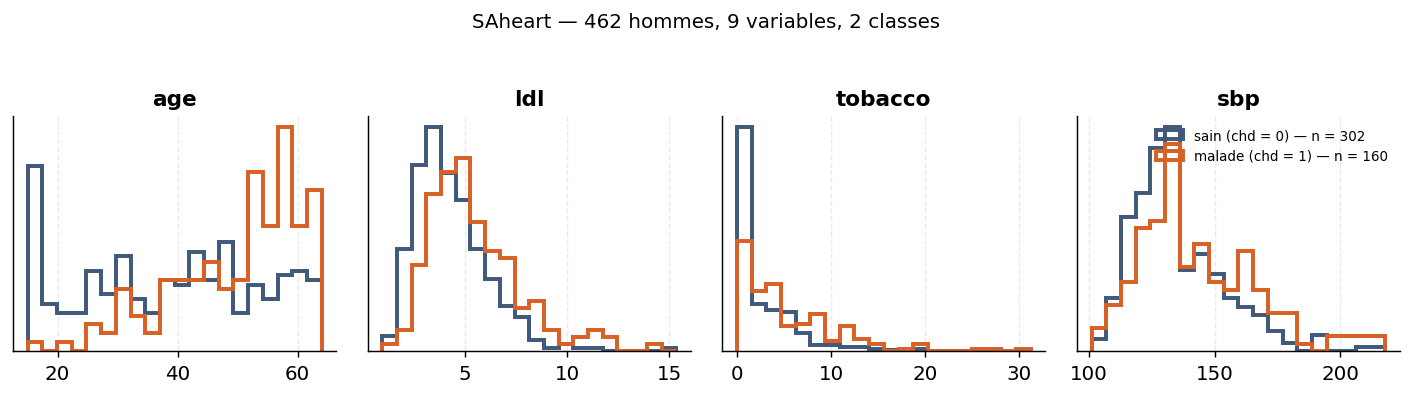

In [19]:
fig = utils.plot_saheart_apercu()

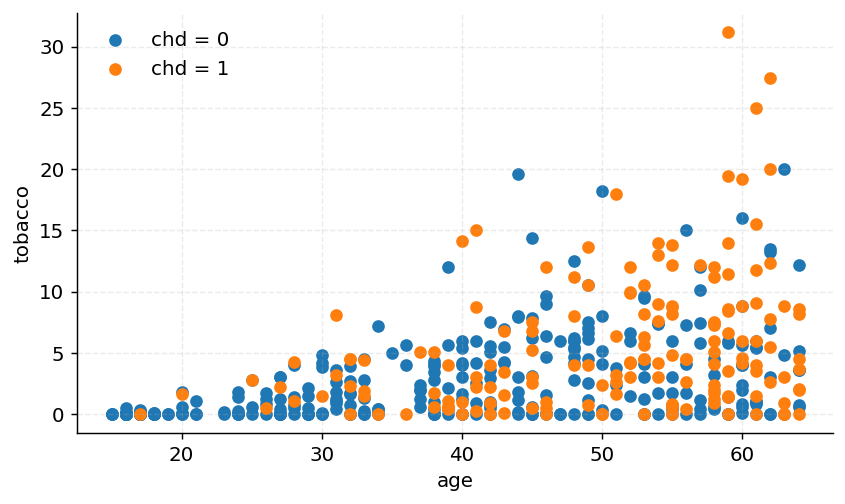

In [20]:
import matplotlib.pyplot as plt

plt.scatter(df[df["chd"] == 0]["age"],
            df[df["chd"] == 0]["tobacco"],
            label="chd = 0")

plt.scatter(df[df["chd"] == 1]["age"],
            df[df["chd"] == 1]["tobacco"],
            label="chd = 1")

plt.xlabel("age")
plt.ylabel("tobacco")
plt.legend()
plt.show()

#### 2.3 1.3 Decouper

In [ ]:
# Sans stratify 
VARIABLES = [

    "sbp", "tobacco", "ldl", "adiposity",
    "typea", "obesity", "alcohol", "age"
]

X = df[VARIABLES].to_numpy()
y = df["chd"].to_numpy()

GRAINE = 42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=GRAINE,
    #stratify=y
)

print("sans stratify")

print("Train :", y_train.mean())
print("Test  :", y_test.mean())

print("Train:") # C1
print(pd.Series(y_train).value_counts(normalize=True))

print("Test:")
print(pd.Series(y_test).value_counts(normalize=True))

print("Proportion train :", y_train.mean()) #C2
print("Proportion test  :", y_test.mean())

sans stratify
Train : 0.34365325077399383
Test  : 0.35251798561151076
Train:
0    0.656347
1    0.343653
Name: proportion, dtype: float64
Test:
0    0.647482
1    0.352518
Name: proportion, dtype: float64
Proportion train : 0.34365325077399383
Proportion test  : 0.35251798561151076


In [35]:
VARIABLES = [
    "sbp", "tobacco", "ldl", "adiposity",
    "typea", "obesity", "alcohol", "age"
]

X = df[VARIABLES].to_numpy()
y = df["chd"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=GRAINE,
    stratify=y
)

print("avec stratify")

print("Train :", y_train.mean())
print("Test  :", y_test.mean())

print("Train:")
print(pd.Series(y_train).value_counts(normalize=True))

print("Test:")
print(pd.Series(y_test).value_counts(normalize=True))

avec stratify
Train : 0.34674922600619196
Test  : 0.34532374100719426
Train:
0    0.653251
1    0.346749
Name: proportion, dtype: float64
Test:
0    0.654676
1    0.345324
Name: proportion, dtype: float64


#### 3.1 2.2 Ecrire la classe

```python
class BayesNaifGaussien:
    """Classifieur de Bayes naïf gaussien, écrit à la main."""

    def fit(self, X, y):
        self.classes_ = np.unique(y)

        # Proportion de chaque classe
        self.pi_ = np.array([
            np.mean(y == k) for k in self.classes_
        ])

        # Moyenne de chaque variable pour chaque classe
        self.mu_ = np.array([
            X[y == k].mean(axis=0) for k in self.classes_
        ])

        # Écart-type de chaque variable pour chaque classe
        self.sigma_ = np.array([
            X[y == k].std(axis=0)
            for k in self.classes_
        ])

        return self

    def _log_densite(self, X, k):
        """log f_k(x) pour chaque ligne de X, sous l'hypothèse naïve."""

        mu = self.mu_[k]
        sigma = self.sigma_[k]

        return np.sum(
            -0.5 * np.log(2 * np.pi)
            - np.log(sigma)
            - (X - mu) ** 2 / (2 * sigma ** 2),
            axis=1
        )

    def predict(self, X):
        log_posterieurs = np.array([
            np.log(self.pi_[k]) + self._log_densite(X, k)
            for k in range(len(self.classes_))
        ])

        indices = np.argmax(log_posterieurs, axis=0)

        return self.classes_[indices]
```


#### 3.2 2.2 Deux erreurs, pas une 